# Experimentos: Gossip Simulator

**Objetivo:** comparar Push, Push-Pull, Push + anti-entropy e fanout adaptativo + anti-entropy em **cobertura, T50/T95 e tráfego**, usando o mesmo modelo de rede e o mesmo orçamento de bytes.

**Hipótese:** a política adaptativa pode reduzir tráfego redundante sem degradar significativamente cobertura e T95.

**Ablação:** a variante `adaptive_ae_quiescent` suspende o Push depois de saturação local. Ela mede quanto tráfego a suspensão remove e se T95, cobertura e recuperação pioram.

**Escala:** o DOE principal usa N=50 a 500. Uma varredura separada (`doe_scale.csv`, 540 execuções) roda as seis variantes em N=1.000, 10.000 e 100.000, com os parâmetros congelados em N=50. Ela mede como T95 e o tráfego por nó crescem com N e se a economia do adaptativo se mantém.

**Fluxo:** validação do simulador, tuning com Optuna em N=50, congelamento dos parâmetros em `configs/tuned.yaml`, execução do DOE, varredura de escala e análise estatística.

**Especificação:** churn, perda, partição, orçamento, métricas e regras do tuning estão definidos no README, seções "Especificação do modelo" e "Fluxo experimental".

> **Template de experimento:** as células comentadas dependem de `run_trial`, `run_manifest` e `summarize_results` (`experiments/helper.py`), de `objective` e `constraints` (`experiments/tuning.py`) e do motor em `src/`. Em `src/` existem o transporte, o Push sem falhas em rede completa e as métricas de cobertura, T50/T95, bytes e duplicatas; políticas, falhas de rede, topologia regular, Push-Pull e anti-entropy ainda não foram implementados. As células das seções 1 e 5 e a curva analítica da seção 2 já executam.

## 1. Imports e configuração

Usar parâmetros declarativos no YAML. O notebook define os estudos Optuna e os gráficos. Ele **não implementa** regras de Gossip, transporte, coleta de métricas ou agendamento de eventos.

In [ ]:
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import yaml

sns.set_theme(style="whitegrid")

# Jupyter normalmente inicia o kernel em experiments/; aceita também iniciar na raiz.
ROOT = Path.cwd().resolve()
if ROOT.name == "experiments":
    ROOT = ROOT.parent

with (ROOT / "configs" / "baseline.yaml").open(encoding="utf-8") as f:
    BASE_CONFIG = yaml.safe_load(f)

# Regras do tuning, fixadas no README.
FAMILIES = ("push", "push_pull", "push_ae", "adaptive_ae")  # quatro famílias do PDF
N_TRIALS = 30  # igual para as quatro famílias
TUNING_SEEDS = list(range(10))
TUNING_SCENARIOS = ("stable", "loss_5pct", "churn_10pct")
QUIESCENCE_GRID = range(1, 11)  # ablação: adaptive_ae congelado, só quiescence_rounds varia

# Seeds de treino não podem coincidir com as do piloto (100..109) nem com as do DOE (1000..1029).
assert not set(TUNING_SEEDS) & (set(range(100, 110)) | set(range(1000, 1030)))

BASE_CONFIG

## 2. Validação do simulador

Rede completa sem falhas, `N=100`, Push com fanout 1 e 3. A curva simulada deve acompanhar a curva analítica antes de qualquer tuning ou benchmark.

A recorrência abaixo é a aproximação de campo médio do Push em rodadas síncronas. Conferir se ela coincide com a fórmula da página 3 do PDF.

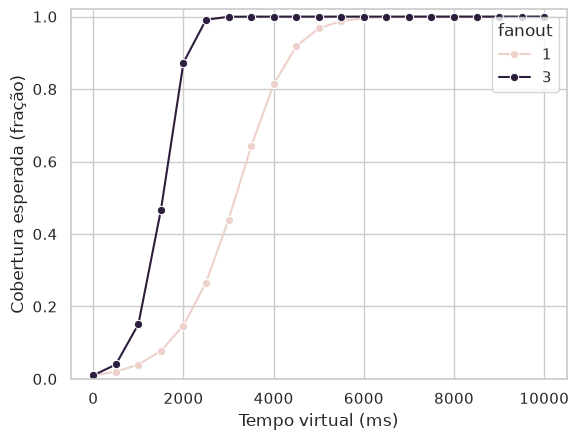

In [2]:
def analytic_push_coverage(n, fanout, rounds):
    """Cobertura esperada do Push em rede completa, sem falhas, em rodadas síncronas.

    Aproximação de campo médio: cada nó infectado escolhe `fanout` peers
    distintos, uniformemente, entre os outros n - 1 nós.
    """
    infected = [1.0]
    for _ in range(rounds):
        i = infected[-1]
        infected.append(i + (n - i) * (1 - (1 - fanout / (n - 1)) ** i))
    return [i / n for i in infected]


ROUNDS = 20
interval_ms = BASE_CONFIG["simulation"]["gossip_interval_ms"]
analytic_df = pd.DataFrame(
    [
        {"time_ms": t * interval_ms, "coverage": c, "fanout": fanout}
        for fanout in (1, 3)
        for t, c in enumerate(analytic_push_coverage(100, fanout, ROUNDS))
    ]
)
assert analytic_df.groupby("fanout")["coverage"].last().gt(0.99).all()

ax = sns.lineplot(data=analytic_df, x="time_ms", y="coverage", hue="fanout", marker="o")
ax.set(xlabel="Tempo virtual (ms)", ylabel="Cobertura esperada (fração)", ylim=(0, 1.02))
plt.show()

In [3]:
# DESCOMENTE após implementar `run_trial` em experiments/helper.py.
# from helper import run_trial
#
# curves = []
# for fanout in (1, 3):
#     config = deepcopy(BASE_CONFIG)  # rede completa, N=100, sem perda
#     # Chave `protocol` proposta; baseline.yaml ainda não a define.
#     config["protocol"] = {"name": "push", "fanout": fanout, "anti_entropy": False}
#     for seed in TUNING_SEEDS:
#         summary, curve = run_trial(config, seed)
#         assert 0 <= summary["coverage_final"] <= 1
#         curves.append(curve.assign(fanout=fanout))
# simulated_df = pd.concat(curves, ignore_index=True)
#
# ax = sns.lineplot(data=simulated_df, x="time_ms", y="coverage", hue="fanout", errorbar=("ci", 95))
# sns.lineplot(
#     data=analytic_df, x="time_ms", y="coverage", hue="fanout",
#     linestyle="--", legend=False, ax=ax,
# )
# ax.set(xlabel="Tempo virtual (ms)", ylabel="Cobertura (fração)", ylim=(0, 1.02))
# plt.show()

## 3. Tuning com Optuna em N=50

Um estudo por família de protocolo, com o mesmo número de trials (`N_TRIALS`) e as mesmas seeds de treino (`TUNING_SEEDS`). O README traz o espaço de busca de cada hiperparâmetro.

| Família | Hiperparâmetros |
|---|---|
| Push | `fanout`, `gossip_interval_ms` |
| Push-Pull | `fanout`, `gossip_interval_ms` |
| Push + AE | `fanout`, `ae_interval_ms`, `gossip_interval_ms` |
| Adaptativo + AE | `min_fanout`, `max_fanout`, `duplicate_threshold`, `timeout_threshold`, `ae_interval_ms` |

Cada trial executa 30 simulações em N=50: os 3 cenários de `TUNING_SCENARIOS` × 10 seeds, com orçamento fixo de 4.096 bytes por nó a cada 1.000 ms.

- **Objetivos:** média de `t95_ms` e média de `bytes_total` nas 30 simulações. Uma simulação sem T95 entra com `duration_ms`.
- **Restrição:** as 30 simulações atingem 95% de cobertura.
- **Tráfego:** o objetivo usa `bytes_total`, porque a quiescência só reduz os bytes enviados depois da saturação.

**Ablação da quiescência:** não há estudo Optuna próprio. `adaptive_ae_quiescent` usa os parâmetros congelados de `adaptive_ae`, e `quiescence_rounds` é escolhido em uma grade de 1 a 10 (`QUIESCENCE_GRID`) com os mesmos cenários, seeds e objetivos. Assim, a diferença entre as duas variantes vem só da quiescência.

In [4]:
# DESCOMENTE após implementar `objective` e `constraints` em experiments/tuning.py.
# import optuna
# from tuning import constraints, objective
#
# tuning_config = deepcopy(BASE_CONFIG)
# tuning_config["network"]["nodes"] = 50
#
# studies = {}
# for family in FAMILIES:
#     study = optuna.create_study(
#         study_name=family,
#         directions=["minimize", "minimize"],  # T95 e bytes
#         # TPE em vez do NSGA-II padrão: com população 50, o NSGA-II
#         # faria apenas amostragem aleatória em 30 trials.
#         sampler=optuna.samplers.TPESampler(seed=0, constraints_func=constraints),
#     )
#     study.optimize(
#         lambda trial: objective(trial, family, tuning_config, TUNING_SEEDS),
#         n_trials=N_TRIALS,
#     )
#     studies[family] = study

In [5]:
# Fronteira de Pareto de cada família (executar depois do tuning):
# fig, ax = plt.subplots(figsize=(8, 4))
# for family, study in studies.items():
#     t95, total_bytes = zip(*(trial.values for trial in study.best_trials))
#     ax.scatter(total_bytes, t95, label=family)
# ax.set(xlabel="Bytes totais enviados", ylabel="T95 (ms)")
# ax.legend()
# plt.show()

## 4. Exportação dos parâmetros otimizados

Cada família fica com uma única configuração, gravada em `configs/tuned.yaml`. A regra de escolha está fixada no README: entre os trials viáveis da fronteira de Pareto, normalizar os dois objetivos entre 0 e 1 e escolher o trial mais próximo de (0, 0); em empate, o de menor `bytes_total`.

A mesma regra escolhe `quiescence_rounds` na grade da ablação.

Depois da exportação, os parâmetros não são reajustados com base nos resultados do DOE. No DOE, `push_f1` é o baseline fixo sem tuning; `push_tuned`, `push_pull`, `push_ae`, `adaptive_ae` e `adaptive_ae_quiescent` leem `configs/tuned.yaml`.

In [ ]:
# DESCOMENTE depois do tuning.
# import numpy as np
#
#
# def select_trial(pareto_trials):
#     """Trial da fronteira de Pareto mais próximo de (0, 0) após normalizar."""
#     values = np.array([trial.values for trial in pareto_trials], dtype=float)
#     span = values.max(axis=0) - values.min(axis=0)
#     normalized = (values - values.min(axis=0)) / np.where(span > 0, span, 1)
#     distance = np.hypot(normalized[:, 0], normalized[:, 1])
#     # Empate: menor bytes_total, que é o segundo objetivo.
#     best = min(range(len(pareto_trials)), key=lambda i: (distance[i], values[i, 1]))
#     return pareto_trials[best]
#
#
# # Conferir que study.best_trials só contém trials viáveis na versão instalada do Optuna.
# tuned = {
#     family: select_trial(study.best_trials).params
#     for family, study in studies.items()
# }
#
# # Ablação: adaptive_ae congelado; só quiescence_rounds varia, em grade.
# grid_study = optuna.create_study(
#     study_name="adaptive_ae_quiescent",
#     directions=["minimize", "minimize"],
#     sampler=optuna.samplers.GridSampler({"quiescence_rounds": list(QUIESCENCE_GRID)}),
# )
# grid_study.optimize(
#     lambda trial: objective(
#         trial, "adaptive_ae_quiescent", tuning_config, TUNING_SEEDS,
#         frozen=tuned["adaptive_ae"],
#     )
# )
# tuned["adaptive_ae_quiescent"] = {
#     **tuned["adaptive_ae"],
#     **select_trial(grid_study.best_trials).params,
# }
#
# with (ROOT / "configs" / "tuned.yaml").open("w", encoding="utf-8") as f:
#     yaml.safe_dump(tuned, f, sort_keys=False)
# tuned

## 5. Carregamento do DOE

Os manifestos em `experiments/doe/` são gerados por `python experiments/doe.py --out experiments/doe`. O notebook carrega os manifestos prontos e não mantém uma lista própria de cenários.

Seeds do piloto: 100..109. Seeds de teste do DOE: 1000..1029.

Seis variantes: `push_f1` (baseline fixo), `push_tuned`, `push_pull`, `push_ae`, `adaptive_ae` e `adaptive_ae_quiescent`. O piloto usa as cinco variantes com tuning.

`doe_scale.csv` é a varredura de escala: cenários estável, perda de 5% e churn de 10%, seis variantes, N=1.000, 10.000 e 100.000, orçamento de 4.096 bytes, seeds 1000..1009. São 540 execuções, fora das 17.640 do plano principal.

In [ ]:
DOE_DIR = ROOT / "experiments" / "doe"
pilot_plan = pd.read_csv(DOE_DIR / "doe_pilot.csv")
full_plan = pd.read_csv(DOE_DIR / "doe_runs.csv")
scale_plan = pd.read_csv(DOE_DIR / "doe_scale.csv")

assert len(pilot_plan) == 600
assert len(full_plan) == 17_640
assert len(scale_plan) == 540

display(pilot_plan.groupby(["scenario", "protocol_variant"]).size().unstack())
display(full_plan.groupby(["phase", "n_nodes"]).size().unstack())
display(scale_plan.groupby(["scenario", "n_nodes"]).size().unstack())

## 6. Execução do piloto e do benchmark completo

Rodar primeiro o piloto de 600 execuções com os parâmetros congelados e inspecionar a qualidade dos dados. Só depois rodar as 17.640 execuções.

Não descartar execuções que não atingem 95% de cobertura: registrar `t95_ms = NaN` e reportar a **fração que atingiu 95%**. A coorte elegível da cobertura são os nós online no instante. Confirmar que todos os protocolos obedecem ao orçamento (dados + controle + reparos).

A varredura de escala roda por último. O custo de uma execução cresce com o número de mensagens, que é proporcional a N. Medido com Push, fanout 1, rede completa, sem falhas e 60 s simulados: 1,4 s em N=1.000, 15,6 s em N=10.000 e 250 s em N=100.000. As 180 execuções de N=100.000 concentram quase todo o tempo.

In [8]:
# DESCOMENTE após implementar `run_manifest` e exportar configs/tuned.yaml.
# from helper import run_manifest
#
#
# def check_quality(summary_df, coverage_df, plan):
#     assert len(summary_df) == len(plan)
#     assert summary_df["coverage_final"].between(0, 1).all()
#     assert coverage_df["coverage"].between(0, 1).all()
#     display(summary_df.isna().sum())
#     reached = (
#         summary_df.assign(reached_t95=summary_df["t95_ms"].notna())
#         .groupby(["scenario", "protocol_variant"])["reached_t95"]
#         .mean()
#         .rename("fraction_reaching_t95")
#     )
#     display(reached.reset_index())
#
#
# pilot_summary, pilot_coverage = run_manifest(pilot_plan)
# check_quality(pilot_summary, pilot_coverage, pilot_plan)

In [ ]:
# DESCOMENTE depois de inspecionar o piloto. São 17.640 execuções.
# summary_df, coverage_df = run_manifest(full_plan)
# check_quality(summary_df, coverage_df, full_plan)
#
# output_dir = ROOT / "results"
# output_dir.mkdir(exist_ok=True)
# summary_df.to_csv(output_dir / "summary.csv", index=False)
# coverage_df.to_csv(output_dir / "coverage.csv", index=False)

In [ ]:
# DESCOMENTE depois do benchmark completo. São 540 execuções da varredura de escala.
# scale_summary, scale_coverage = run_manifest(scale_plan)
# check_quality(scale_summary, scale_coverage, scale_plan)
# scale_summary.to_csv(output_dir / "scale_summary.csv", index=False)

## 7. Análise estatística e visualizações

Agregar por cenário e variante. Reportar mediana, dispersão, fração de execuções com T95 e casos em que o adaptativo **perde** para algum baseline. Comparar cobertura × tempo antes de T95 e bytes, porque T95 não existe nas execuções que nunca atingem 95%.

Os parâmetros foram ajustados em N=50. O gráfico por `n_nodes` mostra se eles mantêm o desempenho em N=100, 250 e 500.

O tráfego tem duas colunas. `bytes_until_t95` é o custo de disseminar a atualização e não depende de `duration_ms`. `bytes_total` inclui o tráfego redundante depois da saturação e cresce com `duration_ms` nas variantes que nunca param de enviar. A ablação da quiescência compara as duas colunas entre `adaptive_ae` e `adaptive_ae_quiescent`.

A varredura de escala junta `summary_df` (N=50 a 500) e `scale_summary` (N=1.000 a 100.000) no cenário estável, com eixo N logarítmico. Em rede completa sem falhas, a teoria do Push prevê cerca de log2(N) + ln(N) rodadas até a cobertura total. Na topologia regular de grau 8 do DOE, espera-se crescimento também logarítmico, com outra constante; nesse caso T95 fica próximo de uma reta no eixo logarítmico. `bytes_until_t95 / n_nodes` é o custo por nó de disseminar a atualização. A coluna `wall_time_s` é o tempo real da execução e mede o custo do simulador, não do protocolo.

In [10]:
# Executar depois de criar summary_df:
# from helper import summarize_results
#
# display(summarize_results(summary_df))

In [11]:
# Cobertura × tempo, cenário estável, N=100, orçamento de 4.096 bytes:
# BUDGET = "budget_bytes_per_node_per_1000ms"
# factors = full_plan[["run_id", "n_nodes", BUDGET]]
# data = coverage_df.merge(factors, on="run_id").query(
#     f"scenario == 'stable' and n_nodes == 100 and {BUDGET} == 4096"
# )
# fig, ax = plt.subplots(figsize=(8, 4))
# sns.lineplot(
#     data=data,
#     x="time_ms", y="coverage", hue="protocol_variant",
#     estimator="mean", errorbar=("ci", 95), ax=ax,
# )
# ax.set(xlabel="Tempo virtual (ms)", ylabel="Cobertura (fração)", ylim=(0, 1.02))
# plt.show()

In [12]:
# T95 × tráfego, perda de 5%:
# data = summary_df.query("scenario == 'loss_5pct'")
# fig, ax = plt.subplots(figsize=(8, 4))
# sns.scatterplot(
#     data=data, x="bytes_total", y="t95_ms",
#     hue="protocol_variant", style="n_nodes", alpha=0.6, ax=ax,
# )
# ax.set(xlabel="Bytes totais enviados", ylabel="T95 (ms)")
# plt.show()

In [13]:
# T95 por tamanho de rede, cenário estável (parâmetros ajustados em N=50):
# data = summary_df.query("scenario == 'stable'")
# fig, ax = plt.subplots(figsize=(8, 4))
# sns.pointplot(
#     data=data, x="n_nodes", y="t95_ms", hue="protocol_variant",
#     estimator="median", errorbar=("pi", 50), ax=ax,
# )
# ax.set(xlabel="Número de nós", ylabel="T95 (ms), mediana e quartis")
# plt.show()

In [ ]:
# Varredura de escala, cenário estável, orçamento de 4.096 bytes: T95 e bytes
# por nó até T95, de N=50 a 100.000. Exige scale_summary (seção 6).
# BUDGET = "budget_bytes_per_node_per_1000ms"
# main = summary_df.merge(full_plan[["run_id", BUDGET]], on="run_id")
# data = pd.concat([main[main[BUDGET] == 4096], scale_summary], ignore_index=True)
# data = data.query("scenario == 'stable'").assign(
#     bytes_per_node_until_t95=lambda d: d["bytes_until_t95"] / d["n_nodes"]
# )
# fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# for ax, column, label in (
#     (axes[0], "t95_ms", "T95 (ms)"),
#     (axes[1], "bytes_per_node_until_t95", "Bytes por nó até T95"),
# ):
#     sns.lineplot(
#         data=data, x="n_nodes", y=column, hue="protocol_variant",
#         estimator="median", errorbar=("pi", 50), marker="o", ax=ax,
#     )
#     ax.set(xscale="log", xlabel="Número de nós (escala log)", ylabel=label)
# plt.show()

In [ ]:
# Ablação da quiescência, N=100: bytes até T95 e bytes totais por cenário.
# variants = ["adaptive_ae", "adaptive_ae_quiescent"]
# data = summary_df.query("protocol_variant in @variants and n_nodes == 100").melt(
#     id_vars=["scenario", "protocol_variant"],
#     value_vars=["bytes_until_t95", "bytes_total"],
#     var_name="metric",
#     value_name="bytes",
# )
# grid = sns.catplot(
#     data=data, kind="bar", x="scenario", y="bytes", hue="protocol_variant",
#     col="metric", estimator="median", errorbar=("pi", 50), sharey=False,
# )
# grid.set_xticklabels(rotation=45, ha="right")
# plt.show()
#
# # Custo da quiescência: recuperação depois da partição (reconexão em t=20 s).
# data = summary_df.query("scenario == 'temporary_partition'")
# ax = sns.boxplot(data=data, x="protocol_variant", y="recovery_ms", hue="n_nodes")
# ax.set(xlabel="Variante", ylabel="Recuperação após a reconexão (ms)")
# ax.tick_params(axis="x", rotation=30)
# plt.show()

### Conclusões (preencher após rodar)

A análise final deve responder: **o adaptativo reduz tráfego sem piorar T95 ou cobertura? Em quais cenários falha?**

- **Validação do baseline:** ...
- **Parâmetros escolhidos no tuning:** ...
- **Cobertura e T95:** ...
- **Tráfego / duplicação:** ...
- **Efeito da escala (N=50 a 500):** ...
- **Varredura de escala (N=1.000 a 100.000):** crescimento de T95 e dos bytes por nó com N; a economia do adaptativo se mantém ou não ...
- **Efeito da quiescência (ablação):** bytes removidos, T95, cobertura e recuperação após partição ...
- **Casos sem ganho do adaptativo:** ...
- **Limitações:** modelo de perdas, topologias, sem rede real e sensibilidade aos parâmetros.